In [ ]:
import os
import os.path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

import tensorflow as tf

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
os.getcwd()

'/content'

In [ ]:
data_path = '/content/drive/My Drive/DSO560/Dataset'

In [ ]:
kaggle = pd.read_csv(os.path.join(data_path, 'train_essays.csv')) # Kaggle training data
kaggle.head()

,id,prompt_id,text,generated
0,0059830c,0,Cars. Cars have been around since they became ...,0
1,005db917,0,Transportation is a large necessity in most co...,0
2,008f63e3,0,"""America's love affair with it's vehicles seem...",0
3,00940276,0,How often do you ride in a car? Do you drive a...,0
4,00c39458,0,Cars are a wonderful thing. They are perhaps o...,0


In [ ]:
argu_train = pd.read_csv(os.path.join(data_path, 'machine-train.csv')) # ArguGPT training data
argu_dev = pd.read_csv(os.path.join(data_path, 'machine-dev.csv')) # ArguGPT develop set data
argu_test = pd.read_csv(os.path.join(data_path, 'machine-test.csv')) # ArguGPT testing data
radek35 = pd.read_csv(os.path.join(data_path, 'ai_generated_train_essays.csv')) # Radek training data (generatede by GPT3.5)
radek4 = pd.read_csv(os.path.join(data_path, 'ai_generated_train_essays_gpt-4.csv')) # Radek training data (generatede by GPT4)

#Standardize Kaggle Dataset

In [ ]:
kaggle_std = pd.DataFrame({
    "id": kaggle["id"],
    "text": kaggle["text"],
    "prompt_id_raw": kaggle["prompt_id"],
    "generated": kaggle["generated"],
    "source_dataset": "kaggle_comp",
    "prompt_text": pd.NA,
    "model_name": "unknown",
    "source_split": "train"
})
kaggle_std

,id,text,prompt_id_raw,generated,source_dataset,prompt_text,model_name,source_split
0,0059830c,Cars. Cars have been around since they became ...,0,0,kaggle_comp,<NA>,unknown,train
1,005db917,Transportation is a large necessity in most co...,0,0,kaggle_comp,<NA>,unknown,train
2,008f63e3,"""America's love affair with it's vehicles seem...",0,0,kaggle_comp,<NA>,unknown,train
3,00940276,How often do you ride in a car? Do you drive a...,0,0,kaggle_comp,<NA>,unknown,train
4,00c39458,Cars are a wonderful thing. They are perhaps o...,0,0,kaggle_comp,<NA>,unknown,train
...,...,...,...,...,...,...,...,...
1373,fe6ff9a5,There has been a fuss about the Elector Colleg...,1,0,kaggle_comp,<NA>,unknown,train
1374,ff669174,Limiting car usage has many advantages. Such a...,0,0,kaggle_comp,<NA>,unknown,train
1375,ffa247e0,There's a new trend that has been developing f...,0,0,kaggle_comp,<NA>,unknown,train
1376,ffc237e9,As we all know cars are a big part of our soci...,0,0,kaggle_comp,<NA>,unknown,train


# Standardize ArguGPT Dataset

In [ ]:
def standardize_argugpt(df, split_name):
    return pd.DataFrame({
        "id": df["id"],
        "prompt_id_raw": df["prompt_id"],
        "text": df["text"],
        "generated": 1,
        "source_dataset": "argugpt",
        "prompt_text": df["prompt"],
        "model_name": df["model"],
        "source_split": split_name
    })
argu_train_std = standardize_argugpt(argu_train, "train")
argu_dev_std = standardize_argugpt(argu_dev, "dev")
argu_test_std = standardize_argugpt(argu_test, "test")

In [ ]:
argu_train_std

,id,prompt_id_raw,text,generated,source_dataset,prompt_text,model_name,source_split
0,weccl_30,WECCL-17,There are many people who think that universit...,1,argugpt,Some people think the university education is ...,text-babbage-001,train
1,weccl_51,WECCL-17,There are a number of reasons why people might...,1,argugpt,Some people think the university education is ...,text-babbage-001,train
2,weccl_48,WECCL-17,There are many reasons why university educatio...,1,argugpt,Some people think the university education is ...,text-babbage-001,train
3,weccl_50,WECCL-17,There are many people who think that universit...,1,argugpt,Some people think the university education is ...,text-babbage-001,train
4,weccl_55,WECCL-17,There is a general consensus that university e...,1,argugpt,Some people think the university education is ...,text-babbage-001,train
...,...,...,...,...,...,...,...,...
3333,gre_1179,GRE-676,Governments play a crucial role in addressing ...,1,argugpt,Governments should focus more on solving the i...,gpt-3.5-turbo,train
3334,gre_1181,GRE-678,"As social beings, humans are naturally incline...",1,argugpt,It is primarily through our identification wit...,gpt-3.5-turbo,train
3335,gre_590,GRE-679,History can often be seen as an abstract conce...,1,argugpt,The study of history has value only to the ext...,text-davinci-003,train
3336,gre_591,GRE-680,I disagree with the statement that it is inapp...,1,argugpt,As long as people in a society are hungry or o...,text-davinci-003,train


In [ ]:
argu_dev_std

,id,prompt_id_raw,text,generated,source_dataset,prompt_text,model_name,source_split
0,weccl_18,WECCL-17,There are a variety of opinions on the purpose...,1,argugpt,Some people think the university education is ...,text-babbage-001,dev
1,weccl_260,WECCL-17,The university education is not only for prepa...,1,argugpt,Some people think the university education is ...,text-curie-001,dev
2,weccl_255,WECCL-17,I believe that the university education is mor...,1,argugpt,Some people think the university education is ...,text-curie-001,dev
3,weccl_652,WECCL-17,University education is a topic of much debate...,1,argugpt,Some people think the university education is ...,text-davinci-003,dev
4,weccl_744,WECCL-17,The purpose of university education has been a...,1,argugpt,Some people think the university education is ...,gpt-3.5-turbo,dev
...,...,...,...,...,...,...,...,...
345,gre_514,GRE-603,The notion that one must be forced to defend a...,1,argugpt,Only by being forced to defend an idea against...,text-davinci-003,dev
346,gre_1107,GRE-604,I strongly agree with the statement that menta...,1,argugpt,Students should be encouraged to realize that ...,gpt-3.5-turbo,dev
347,gre_1163,GRE-660,"In today’s world, where competition is highly ...",1,argugpt,The best preparation for life or a career is n...,gpt-3.5-turbo,dev
348,gre_1174,GRE-671,Education is one of the most powerful tools th...,1,argugpt,AII nations should help support the developmen...,gpt-3.5-turbo,dev


In [ ]:
argu_test_std

,id,prompt_id_raw,text,generated,source_dataset,prompt_text,model_name,source_split
0,weccl_45,WECCL-17,There are many different opinions on whether o...,1,argugpt,Some people think the university education is ...,text-babbage-001,test
1,weccl_264,WECCL-17,The university education is not only for prepa...,1,argugpt,Some people think the university education is ...,text-curie-001,test
2,weccl_648,WECCL-17,"University education is a contentious issue, w...",1,argugpt,Some people think the university education is ...,text-davinci-003,test
3,weccl_741,WECCL-17,University education has always been a topic o...,1,argugpt,Some people think the university education is ...,gpt-3.5-turbo,test
4,weccl_3024,WECCL-17,The college is not only a time of preparition ...,1,argugpt,Some people think the university education is ...,gpt2-xl,test
...,...,...,...,...,...,...,...,...
345,gre_1097,GRE-594,In a world where individualism is highly value...,1,argugpt,People today are too individualistic. Instead ...,gpt-3.5-turbo,test
346,gre_1104,GRE-601,"In the modern era, the accumulation of knowled...",1,argugpt,The increase in knowledge is forcing people to...,gpt-3.5-turbo,test
347,gre_525,GRE-614,The true strength of a country is not defined ...,1,argugpt,The true strength of a country is best demonst...,text-davinci-003,test
348,gre_538,GRE-627,I agree that society should identify those chi...,1,argugpt,Society should identify those children who hav...,text-davinci-003,test


# Standardize Radek Dataset

In [ ]:
def standardize_radek(df, model_name):
    return pd.DataFrame({
        "id": df["id"],
        "prompt_id_raw": df["prompt_id"],
        "text": df["text"],
        "generated": df["generated"],
        "source_dataset": "radek",
        "prompt_text": pd.NA,
        "model_name": model_name,
        "source_split": "train"
    })

radek35_std = standardize_radek(radek35, "gpt-3.5-turbo")
radek4_std = standardize_radek(radek4, "gpt-4")

In [ ]:
radek35_std

,id,prompt_id_raw,text,generated,source_dataset,prompt_text,model_name,source_split
0,d429f032,0,Advantages of Limiting Car Usage \n\nLimiting ...,1,radek,<NA>,gpt-3.5-turbo,train
1,1ce279be,0,Advantages of Limiting Car Usage\n\nLimiting c...,1,radek,<NA>,gpt-3.5-turbo,train
2,c9595213,0,Limiting car usage has numerous advantages tha...,1,radek,<NA>,gpt-3.5-turbo,train
3,f2266d87,0,The passages provided discuss the advantages o...,1,radek,<NA>,gpt-3.5-turbo,train
4,eeace4bd,0,Title: The Advantages of Limiting Car Usage\n\...,1,radek,<NA>,gpt-3.5-turbo,train
...,...,...,...,...,...,...,...,...
495,c67009a2,1,"[Your Name]\n[Your Address]\n[City, State, ZIP...",1,radek,<NA>,gpt-3.5-turbo,train
496,66e830cc,1,"[Your Name]\n[Your Address]\n[City, State, Zip...",1,radek,<NA>,gpt-3.5-turbo,train
497,5d70a380,1,"[Your Name]\n[Your Address]\n[City, State, ZIP...",1,radek,<NA>,gpt-3.5-turbo,train
498,9a07aa27,1,"[Your Name]\n[Your Address]\n[City, State, ZIP...",1,radek,<NA>,gpt-3.5-turbo,train


In [ ]:
radek4_std

,id,prompt_id_raw,text,generated,source_dataset,prompt_text,model_name,source_split
0,d62377cd,0,Title: The Benefits of Limiting Car Usage: Ins...,1,radek,<NA>,gpt-4,train
1,d721137f,0,Title: The Benefits of Limiting Car Usage\n\nI...,1,radek,<NA>,gpt-4,train
2,afc4d9ce,0,Title: The Advantages of Curtailing Car Usage:...,1,radek,<NA>,gpt-4,train
3,1dd6eddd,0,Title: The Benefits of Limiting Car Usage\n\nH...,1,radek,<NA>,gpt-4,train
4,9baa7169,0,Title: Advantages of Limiting Car Usage: A Ste...,1,radek,<NA>,gpt-4,train
...,...,...,...,...,...,...,...,...
195,47bddafc,1,"Dear Senator [Your Senator's Name],\n\nI am wr...",1,radek,<NA>,gpt-4,train
196,76e1300e,1,"Dear Senator,\n\nI am writing today to express...",1,radek,<NA>,gpt-4,train
197,05058b6b,1,"Dear Senator,\n\nI hope this letter finds you ...",1,radek,<NA>,gpt-4,train
198,1887e7ab,1,"Senator [Your Senator’s Name],\n\nI am a const...",1,radek,<NA>,gpt-4,train


# Merge and separate the dataset

In [ ]:
merged = pd.concat([
    kaggle_std,
    argu_train_std, argu_dev_std, argu_test_std,
    radek35_std, radek4_std
], ignore_index=True)
merged

,id,text,prompt_id_raw,generated,source_dataset,prompt_text,model_name,source_split
0,0059830c,Cars. Cars have been around since they became ...,0,0,kaggle_comp,<NA>,unknown,train
1,005db917,Transportation is a large necessity in most co...,0,0,kaggle_comp,<NA>,unknown,train
2,008f63e3,"""America's love affair with it's vehicles seem...",0,0,kaggle_comp,<NA>,unknown,train
3,00940276,How often do you ride in a car? Do you drive a...,0,0,kaggle_comp,<NA>,unknown,train
4,00c39458,Cars are a wonderful thing. They are perhaps o...,0,0,kaggle_comp,<NA>,unknown,train
...,...,...,...,...,...,...,...,...
6111,47bddafc,"Dear Senator [Your Senator's Name],\n\nI am wr...",1,1,radek,<NA>,gpt-4,train
6112,76e1300e,"Dear Senator,\n\nI am writing today to express...",1,1,radek,<NA>,gpt-4,train
6113,05058b6b,"Dear Senator,\n\nI hope this letter finds you ...",1,1,radek,<NA>,gpt-4,train
6114,1887e7ab,"Senator [Your Senator’s Name],\n\nI am a const...",1,1,radek,<NA>,gpt-4,train


In [ ]:
human_df = merged[merged["generated"] == 0]
human_df

,id,text,prompt_id_raw,generated,source_dataset,prompt_text,model_name,source_split
0,0059830c,Cars. Cars have been around since they became ...,0,0,kaggle_comp,<NA>,unknown,train
1,005db917,Transportation is a large necessity in most co...,0,0,kaggle_comp,<NA>,unknown,train
2,008f63e3,"""America's love affair with it's vehicles seem...",0,0,kaggle_comp,<NA>,unknown,train
3,00940276,How often do you ride in a car? Do you drive a...,0,0,kaggle_comp,<NA>,unknown,train
4,00c39458,Cars are a wonderful thing. They are perhaps o...,0,0,kaggle_comp,<NA>,unknown,train
...,...,...,...,...,...,...,...,...
1373,fe6ff9a5,There has been a fuss about the Elector Colleg...,1,0,kaggle_comp,<NA>,unknown,train
1374,ff669174,Limiting car usage has many advantages. Such a...,0,0,kaggle_comp,<NA>,unknown,train
1375,ffa247e0,There's a new trend that has been developing f...,0,0,kaggle_comp,<NA>,unknown,train
1376,ffc237e9,As we all know cars are a big part of our soci...,0,0,kaggle_comp,<NA>,unknown,train


In [ ]:
ai_df = merged[merged["generated"] == 1]
ai_df

,id,text,prompt_id_raw,generated,source_dataset,prompt_text,model_name,source_split
704,82131f68,"This essay will analyze, discuss and prove one...",1,1,kaggle_comp,<NA>,unknown,train
740,86fe4f18,I strongly believe that the Electoral College ...,1,1,kaggle_comp,<NA>,unknown,train
1262,eafb8a56,"Limiting car use causes pollution, increases c...",0,1,kaggle_comp,<NA>,unknown,train
1378,weccl_30,There are many people who think that universit...,WECCL-17,1,argugpt,Some people think the university education is ...,text-babbage-001,train
1379,weccl_51,There are a number of reasons why people might...,WECCL-17,1,argugpt,Some people think the university education is ...,text-babbage-001,train
...,...,...,...,...,...,...,...,...
6111,47bddafc,"Dear Senator [Your Senator's Name],\n\nI am wr...",1,1,radek,<NA>,gpt-4,train
6112,76e1300e,"Dear Senator,\n\nI am writing today to express...",1,1,radek,<NA>,gpt-4,train
6113,05058b6b,"Dear Senator,\n\nI hope this letter finds you ...",1,1,radek,<NA>,gpt-4,train
6114,1887e7ab,"Senator [Your Senator’s Name],\n\nI am a const...",1,1,radek,<NA>,gpt-4,train


After separate the megered dataset into human and ai, we found out that the human_df contains 1375 rows but ai_df has 4741 rows which is much more. To eliminate the potential bias on the model, we randomly draw the same number of raws from ai_df as the human_df.

In [ ]:
random_ai_df = ai_df.sample(n=len(human_df), random_state=42)
random_ai_df

,id,text,prompt_id_raw,generated,source_dataset,prompt_text,model_name,source_split
5696,808f2b8f,"[Your Name]\n[Your Address]\n[City, State, ZIP...",1,1,radek,<NA>,gpt-3.5-turbo,train
4624,gre_1077,"In today's society, the importance of career p...",GRE-574,1,argugpt,Instead of requiring students to take courses ...,gpt-3.5-turbo,train
5165,weccl_4796,"Nowadays, most of us send electronic cards for...",WECCL-14,1,argugpt,"Nowadays, we are advised by environmentalists ...",gpt2-xl,test
1804,weccl_609,There are a few schools of thought in regards ...,WECCL-23,1,argugpt,Some people think children should learn to com...,text-davinci-002,train
1840,weccl_717,The debate on whether children should be taugh...,WECCL-23,1,argugpt,Some people think children should learn to com...,text-davinci-003,train
...,...,...,...,...,...,...,...,...
1641,weccl_577,There are many different opinions about whethe...,WECCL-02,1,argugpt,Some people think that education is a life-lon...,text-davinci-002,train
3548,toefl_1107,"There are many different ways to travel, and e...",TOEFL11-06,1,argugpt,The best way to travel is in a group led by a ...,text-davinci-002,train
2489,weccl_4557,With the higher-speed development of the whole...,WECCL-15,1,argugpt,Some people say the government shouldn't put m...,gpt2-xl,train
1438,weccl_420,There are many different opinions on what the ...,WECCL-17,1,argugpt,Some people think the university education is ...,text-davinci-001,train


In [ ]:
balanced_merge_df = pd.concat([human_df, random_ai_df], ignore_index=True).sample(frac=1, random_state=42)
balanced_merge_df

,id,text,prompt_id_raw,generated,source_dataset,prompt_text,model_name,source_split
1399,weccl_1076,There is no one answer to this question as it ...,WECCL-08,1,argugpt,"In the western world, if a family member has g...",text-babbage-001,train
978,afe7cdd4,"Dear State Senator, I do not like the Electora...",1,0,kaggle_comp,<NA>,unknown,train
2168,weccl_876,Famous people are often the subject of media a...,WECCL-10,1,argugpt,Some people think that famous people are treat...,text-curie-001,train
2232,toefl_726,It is certainly true that young people today d...,TOEFL11-03,1,argugpt,Young people nowadays do not give enough time ...,text-davinci-001,train
527,654fd2b7,The United States of America has come a long w...,1,0,kaggle_comp,<NA>,unknown,train
...,...,...,...,...,...,...,...,...
1638,toefl_805,There is no question that the automotive lands...,TOEFL11-05,1,argugpt,"In twenty years, there will be fewer cars in u...",text-davinci-001,train
1095,c7f747cb,"Dear State Senator , I wrote this letter to yo...",1,0,kaggle_comp,<NA>,unknown,train
1130,d043ff9f,We should abolish the Electoral College and ch...,1,0,kaggle_comp,<NA>,unknown,train
1294,f08a38d0,"Dear State Senator, While I understand that th...",1,0,kaggle_comp,<NA>,unknown,train


# Check Dataset and EDA

In [ ]:
balanced_merge_df.shape

(2750, 8)

In [ ]:
balanced_merge_df["generated"].value_counts()

,count
generated,
1,1375
0,1375


In [ ]:
pd.crosstab(balanced_merge_df["source_dataset"], balanced_merge_df["generated"])

generated,0,1
source_dataset,,
argugpt,0,1173
kaggle_comp,1375,0
radek,0,202


In [ ]:
balanced_merge_df.isna().sum()

,0
id,0
text,0
prompt_id_raw,0
generated,0
source_dataset,0
prompt_text,1577
model_name,0
source_split,0


In [ ]:
balanced_merge_df.duplicated(subset=["text"]).sum()

np.int64(0)

In [ ]:
balanced_merge_df["word_count"] = balanced_merge_df["text"].apply(lambda x: len(str(x).split()))

In [ ]:
balanced_merge_df["word_count"].describe()

,word_count
count,2750.000000
mean,438.707636
std,192.287631
min,50.000000
25%,313.000000
50%,437.000000
75%,549.000000
max,1360.000000


In [ ]:
balanced_merge_df["char_count"] = balanced_merge_df["text"].apply(lambda x: len(str(x)))

In [ ]:
balanced_merge_df["char_count"].describe()

,char_count
count,2750.000000
mean,2576.732364
std,1117.307294
min,275.000000
25%,1861.250000
50%,2580.000000
75%,3217.750000
max,8436.000000


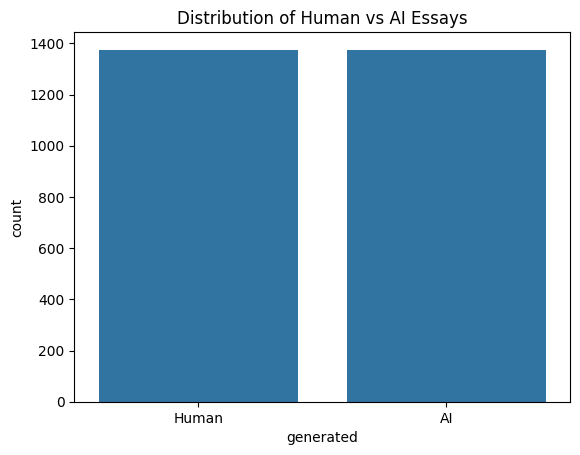

In [ ]:
sns.countplot(data=balanced_merge_df, x="generated")
plt.title("Distribution of Human vs AI Essays")
plt.xticks([0, 1], ["Human", "AI"])
plt.show()

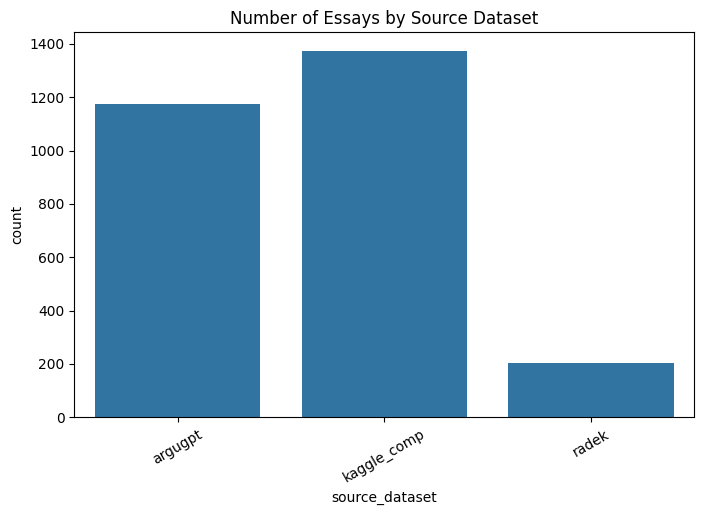

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=balanced_merge_df, x="source_dataset")
plt.title("Number of Essays by Source Dataset")
plt.xticks(rotation=30)
plt.show()


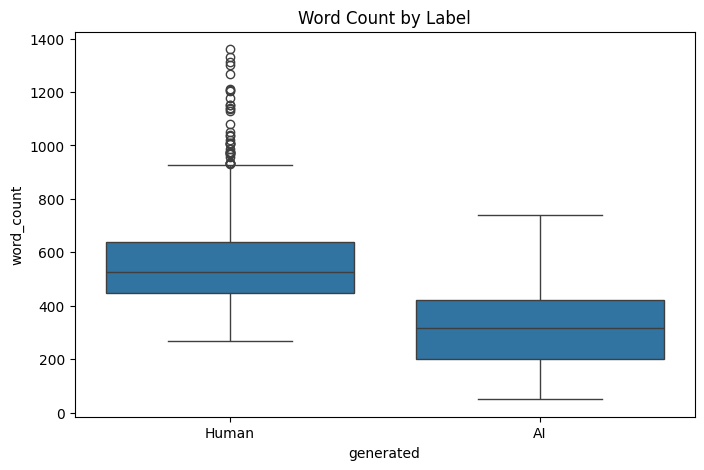

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=balanced_merge_df, x="generated", y="word_count")
plt.title("Word Count by Label")
plt.xticks([0, 1], ["Human", "AI"])
plt.show()


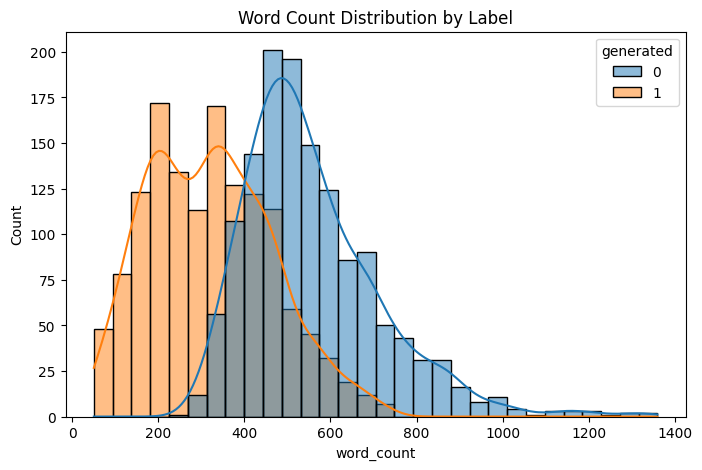

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(data=balanced_merge_df, x="word_count", hue="generated", bins=30, kde=True)
plt.title("Word Count Distribution by Label")
plt.show()


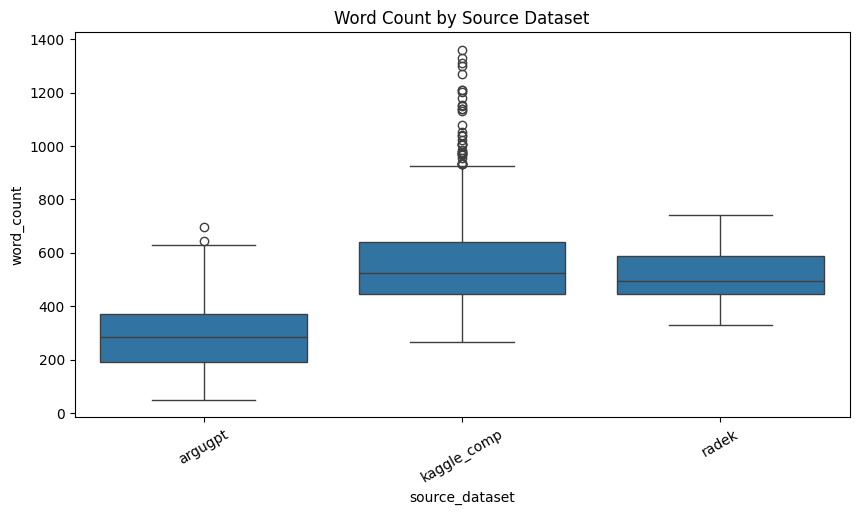

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=balanced_merge_df, x="source_dataset", y="word_count")
plt.title("Word Count by Source Dataset")
plt.xticks(rotation=30)
plt.show()


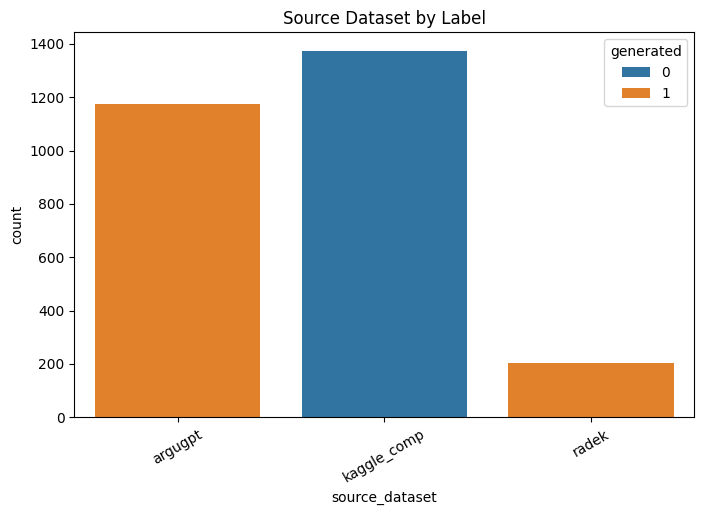

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=balanced_merge_df, x="source_dataset", hue="generated")
plt.title("Source Dataset by Label")
plt.xticks(rotation=30)
plt.show()


One problem we have now is that ArguGPT dataset contains most of the ai-generated essays which may lead to classification bias. For example, if we use this data to fit the model, the model would learn the data from different sources but not whether generated by human or ai. Therefore, we think we should separate the dataset again; one is kaggle and radek combined dataset used for the main model, which is identify whether the essay is writte by human or AI. Another extended dataset which combines the three datasets to find out that if we add more AI generated essays into the model, would it perform better or it would learn more source-specific patterns.

# Main Dataset

In [ ]:
dataset_A = balanced_merge_df[
    balanced_merge_df["source_dataset"].isin(["kaggle_comp", "radek"])
].copy()

human_A = dataset_A[dataset_A["generated"] == 0]
ai_A = dataset_A[dataset_A["generated"] == 1]

human_A_sample = human_A.sample(n=len(ai_A), random_state=42)

dataset_A_balanced = pd.concat([human_A_sample, ai_A], ignore_index=True).sample(frac=1, random_state=42)


In [ ]:
dataset_A_balanced["generated"].value_counts()

,count
generated,
0,202
1,202


In [ ]:
pd.crosstab(dataset_A_balanced["source_dataset"], dataset_A_balanced["generated"])

generated,0,1
source_dataset,,
kaggle_comp,202,0
radek,0,202


In [ ]:
dataset_A_balanced.to_csv(os.path.join(data_path, "main_balanced.csv"), index=False) # this is the one we will use for our main model
dataset_A.to_csv(os.path.join(data_path, "main_full.csv"), index=False)

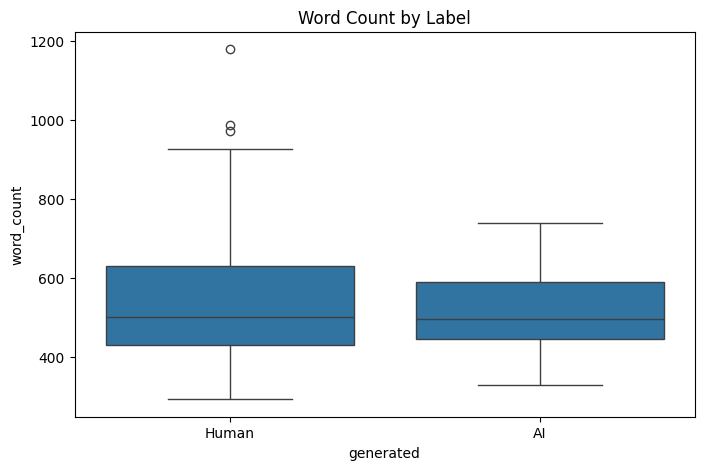

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=dataset_A_balanced, x="generated", y="word_count")
plt.title("Word Count by Label")
plt.xticks([0, 1], ["Human", "AI"])
plt.show()


# Extended Dataset

The current balanced_merge_df could be used as the extended dataset

In [ ]:
extended_df = balanced_merge_df
extended_df.to_csv(os.path.join(data_path, "extended.csv"), index=False)